In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/raw/train.csv.gz")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They wer...,0,0,0,0,0,0
1,000103f0d9cfb60f,"D'aww! He matches this background colour I'm seemingly stuck with. Thanks. (talk) 21:51, Januar...",0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It's just that this guy is constantly removing relev...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on improvement - I wondered if the section statistics...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember what page that's on?",0,0,0,0,0,0


In [4]:
df.shape

(159571, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   id             159571 non-null  str  
 1   comment_text   159571 non-null  str  
 2   toxic          159571 non-null  int64
 3   severe_toxic   159571 non-null  int64
 4   obscene        159571 non-null  int64
 5   threat         159571 non-null  int64
 6   insult         159571 non-null  int64
 7   identity_hate  159571 non-null  int64
dtypes: int64(6), str(2)
memory usage: 9.7 MB


In [6]:
# Define the six target labels
label_cols = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

# Count positive samples for each label
label_counts = df[label_cols].sum()

# Calculate the percentage of positive samples
label_percentages = df[label_cols].mean() * 100

# Combine results into a DataFrame
label_summary = pd.DataFrame({
    "Positive_Count": label_counts,
    "Positive_Percentage": label_percentages
})

label_summary = label_summary.sort_values(
    by="Positive_Count",
    ascending=False
)

label_summary

,Positive_Count,Positive_Percentage
toxic,15294,9.584448
obscene,8449,5.294822
insult,7877,4.936361
severe_toxic,1595,0.999555
identity_hate,1405,0.880486
threat,478,0.299553


In [7]:
# Count the number of positive labels for each comment
df["num_labels"] = df[label_cols].sum(axis=1)

# Count comments by the number of positive labels
label_distribution = df["num_labels"].value_counts().sort_index()

# Calculate percentages
label_distribution_pct = (
    label_distribution / len(df) * 100
)

# Combine into a summary table
overlap_summary = pd.DataFrame({
    "Comment_Count": label_distribution,
    "Percentage": label_distribution_pct
})

overlap_summary

,Comment_Count,Percentage
num_labels,,
0,143346,89.832112
1,6360,3.985687
2,3480,2.180847
3,4209,2.637697
4,1760,1.102957
5,385,0.241272
6,31,0.019427


In [8]:
# Calculate the number of characters in each comment
df["char_length"] = df["comment_text"].str.len()

# Calculate descriptive statistics
df["char_length"].describe()

count    159571.000000
mean        394.073221
std         590.720282
min           6.000000
25%          96.000000
50%         205.000000
75%         435.000000
max        5000.000000
Name: char_length, dtype: float64

In [9]:
# Calculate the number of words in each comment
df["word_count"] = df["comment_text"].str.split().str.len()

# Display descriptive statistics
df["word_count"].describe()

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: word_count, dtype: float64

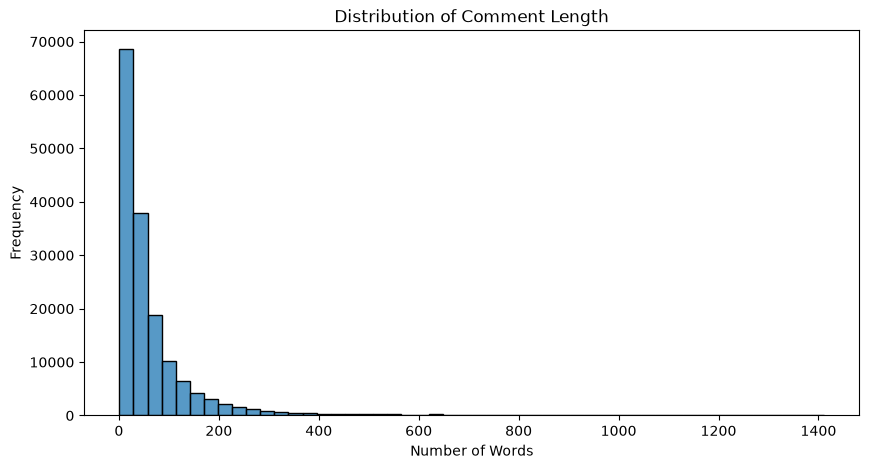

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Comment Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

95th percentile: 230.0


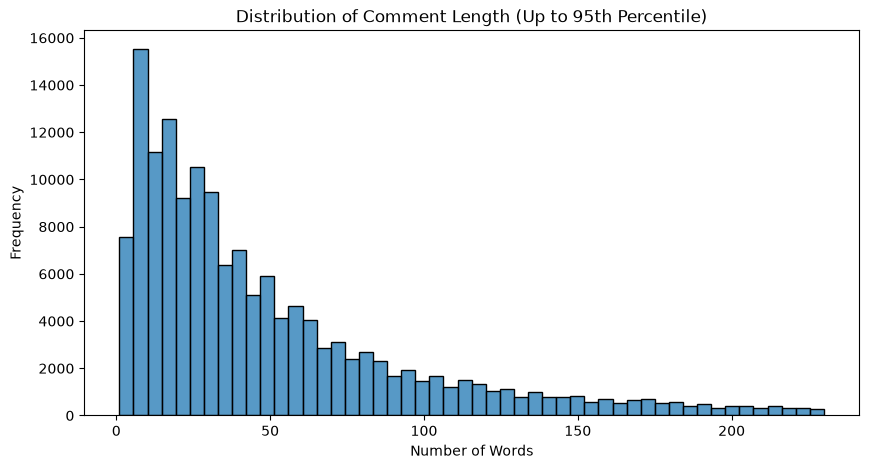

In [11]:
# Calculate the 95th percentile of word count
word_95 = df["word_count"].quantile(0.95)

print("95th percentile:", word_95)

# Plot the distribution within the 95th percentile
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["word_count"] <= word_95],
    x="word_count",
    bins=50
)

plt.title("Distribution of Comment Length (Up to 95th Percentile)")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [12]:
# Check duplicated comment IDs
print("Duplicated IDs:", df["id"].duplicated().sum())

# Check duplicated comment texts
print("Duplicated comments:", df["comment_text"].duplicated().sum())

# Check missing values
print(df.isnull().sum())

Duplicated IDs: 0
Duplicated comments: 0
id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
num_labels       0
char_length      0
word_count       0
dtype: int64


In [13]:

# Compare comment length between toxic and non-toxic comments

length_comparison = df.groupby("toxic")["word_count"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

length_comparison.index = ["Non-toxic", "Toxic"]

length_comparison


,count,mean,median,std,min,max
Non-toxic,144277,68.967874,38.0,98.279574,1,1250
Toxic,15294,51.289787,22.0,106.475663,2,1411


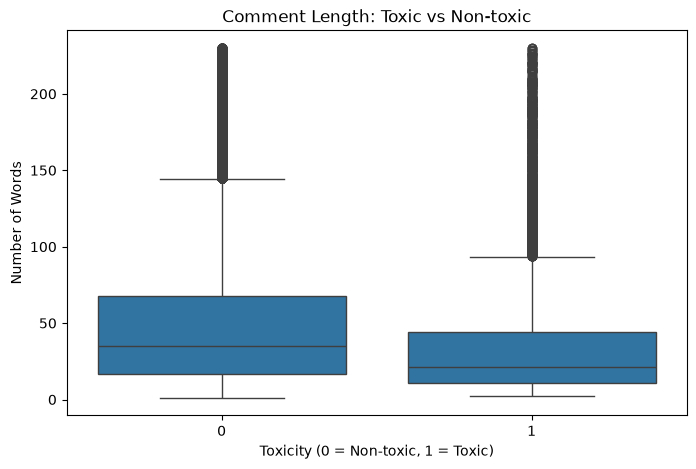

In [14]:

# Compare comment length using a boxplot

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[df["word_count"] <= word_95],
    x="toxic",
    y="word_count"
)

plt.title("Comment Length: Toxic vs Non-toxic")
plt.xlabel("Toxicity (0 = Non-toxic, 1 = Toxic)")
plt.ylabel("Number of Words")

plt.show()


In [15]:

from scipy.stats import mannwhitneyu

# Separate the two groups
non_toxic = df[df["toxic"] == 0]["word_count"]
toxic = df[df["toxic"] == 1]["word_count"]

# Perform Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    toxic,
    non_toxic,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_value)



Mann-Whitney U statistic: 842206117.0
P-value: 0.0


In [16]:

# Calculate rank-biserial correlation

n_toxic = len(toxic)
n_non_toxic = len(non_toxic)

rank_biserial = (
    2 * u_statistic / (n_toxic * n_non_toxic)
) - 1

print("Rank-biserial correlation:", rank_biserial)


Rank-biserial correlation: -0.23663859613567784
